In [1]:
import pandas as pd

In [2]:
dataset=pd.read_csv("FP&A_Time_Series_Capstone_Dataset.csv")

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Client Name         120 non-null    object
 1   Month               120 non-null    object
 2   Scenario            120 non-null    object
 3   Revenue GL Account  120 non-null    object
 4   Revenue             120 non-null    object
 5   Cost GL Account     120 non-null    object
 6   Cost                120 non-null    object
 7   CCI                 120 non-null    object
 8   CCI %               120 non-null    object
dtypes: object(9)
memory usage: 8.6+ KB


In [5]:
#dataset['Revenue'] = pd.to_numeric(dataset['Revenue'].astype(str).str.replace(',', '', regex=False).str.replace(' ', '', regex=True))#regex=regualr expression True means more than one expression, False means only one expresion
dataset['Revenue'] = pd.to_numeric(dataset['Revenue'].astype(str).str.replace(r'[,\s]','', regex=True))
dataset['Cost']=pd.to_numeric(dataset['Cost'].astype(str).str.replace(r'[,\s]',"",regex=True))
dataset['CCI']=pd.to_numeric(dataset['CCI'].astype(str).str.replace(r'[,\s]',"",regex=True))
dataset['CCI %']=pd.to_numeric(dataset['CCI %'].astype(str).str.replace(r'[%,\s]',"",regex=True))
dataset['Month']=pd.to_datetime(dataset['Month'],format='%b-%y')

In [6]:
dataset.head()

,Client Name,Month,Scenario,Revenue GL Account,Revenue,Cost GL Account,Cost,CCI,CCI %
0,Client A,2025-01-01,Actual,400000 - Revenue,965265.51,500000 - Cost,667654.97,297610.54,30.83
1,Client A,2025-02-01,Actual,400000 - Revenue,994900.11,500000 - Cost,703916.22,290983.89,29.25
2,Client A,2025-03-01,Actual,400000 - Revenue,988177.46,500000 - Cost,681429.95,306747.51,31.04
3,Client A,2025-04-01,Actual,400000 - Revenue,1049206.88,500000 - Cost,731790.39,317416.49,30.25
4,Client A,2025-05-01,Actual,400000 - Revenue,1069524.81,500000 - Cost,741368.55,328156.26,30.68


In [7]:
dataset.dtypes

Client Name                   object
Month                 datetime64[ns]
Scenario                      object
Revenue GL Account            object
Revenue                      float64
Cost GL Account               object
Cost                         float64
CCI                          float64
CCI %                        float64
dtype: object

In [8]:
class Descriptive():

    def quanqual(self, dataset):

        Quan = []
        Qual = []
        Date = []

        for column in dataset.columns:

            if pd.api.types.is_numeric_dtype(dataset[column]):
                Quan.append(column)

            elif pd.api.types.is_datetime64_any_dtype(dataset[column]):
                Date.append(column)

            else:
                Qual.append(column)

        return Quan, Qual, Date


In [9]:
Quan,Qual,Date=Descriptive().quanqual(dataset)
print("Quantitative",Quan)
print("Qualitative",Qual)
print("Date format",Date)

Quantitative ['Revenue', 'Cost', 'CCI', 'CCI %']
Qualitative ['Client Name', 'Scenario', 'Revenue GL Account', 'Cost GL Account']
Date format ['Month']


In [10]:
from Descriptive import Descriptive
obj=Descriptive()

In [11]:
des_data=obj.descriptive_Analysis(dataset,Quan)
des_data

d:\Karthick babu\Learning\10.Time series\Capstone project\Descriptive.py:24: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  des_data[i]["Null_count"]=dataset[i].isnull().sum()
d:\Karthick babu\Learning\10.Time series\Capstone project\Descript

,Revenue,Cost,CCI,CCI %
Null_count,0,0,0,0
NonNull_count,120,120,120,120
Total_Count,120,120,120,120
Mean,779696.375667,554554.371583,225142.004083,28.564083
Median,764281.44,519960.355,227637.95,28.245
Mode,378380.95,271176.98,107203.97,32.31
Std,272157.161796,187538.542747,87086.096805,2.470308
Min,378380.95,271176.98,107203.97,23.91
Q1:25%,539568.3475,401626.885,142257.185,26.755
Q2:50%,764281.44,519960.355,227637.95,28.245


In [12]:
def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color='Red')
    pyplot.axvline(endrange,color='Red')
    # generate a sample
    sample = dataset
    # calculate parameters
    sample_mean =sample.mean()
    sample_std = sample.std()
    print('Mean=%.3f, Standard Deviation=%.3f' % (sample_mean, sample_std))
    # define the distribution
    dist = norm(sample_mean, sample_std)
    
    # sample probabilities for a range of outcomes
    values = [value for value in range(startrange, endrange)]
    probabilities = [dist.pdf(value) for value in values]    
    prob=sum(probabilities)
    print("The area between range({},{}):{}".format(startrange,endrange,sum(probabilities)))
    return prob

    

C:\Users\ADMN\AppData\Local\Temp\ipykernel_3416\1982654439.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')


Mean=779696.376, Standard Deviation=272157.162
The area between range(300000,500000):0.11305838977247777


np.float64(0.11305838977247777)

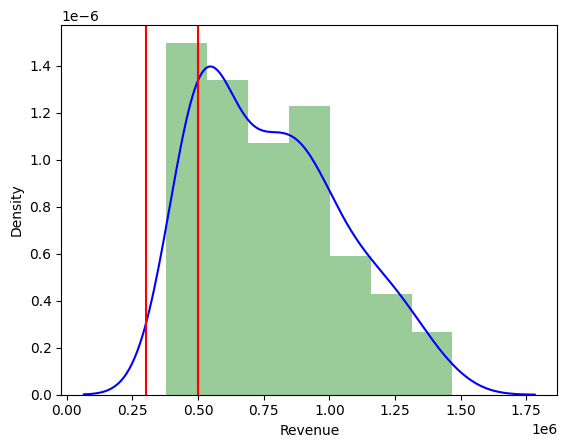

In [13]:
get_pdf_probability(dataset["Revenue"],300000,500000)

In [14]:
def stdNBgraph(dataset):
        # Coverted to standard Normal Distribution
    import seaborn as sns
    mean=dataset.mean()
    std=dataset.std()

    values=[i for i in dataset]

    z_score=[((j-mean)/std) for j in values]

    sns.distplot(z_score,kde=True)

    sum(z_score)/len(z_score)
    #z_score.std()


C:\Users\ADMN\AppData\Local\Temp\ipykernel_3416\2909774602.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(z_score,kde=True)


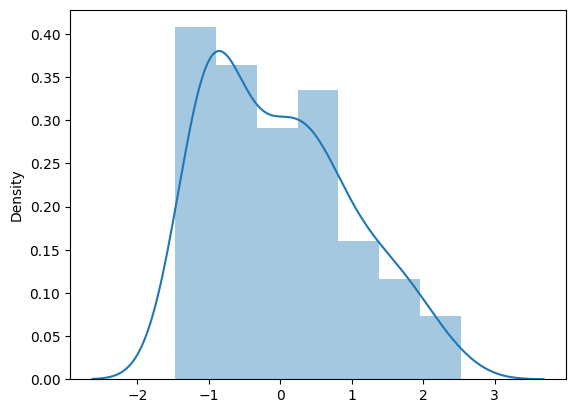

In [25]:
stdNBgraph(dataset["Revenue"])